# IPP Practical File 2

Swanand Wirkar 20251051 BDA

## Problem Statement

Problem 4: JPEG Block Artifact Analysis
Implement 8×8 block-based JPEG-style compression using DCT and quantisation. Compress the same image at low, medium and high quantisation. Analyse block artifacts, lost texture, PSNR and SSIM.

Low quantisation (higher quality): PSNR=48.01 dB, SSIM=0.9971
Medium quantisation: PSNR=37.47 dB, SSIM=0.9738
High quantisation (lower quality): PSNR=29.08 dB, SSIM=0.8848


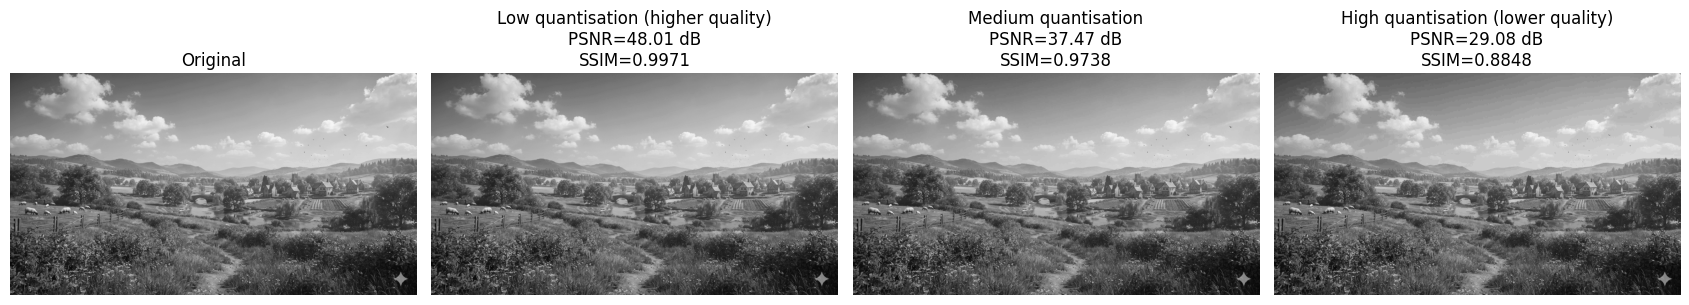

Block artifacts are most visible near 8×8 boundaries, especially with stronger quantisation. Fine textures disappear because small DCT coefficients are rounded aggressively. PSNR and SSIM generally decrease as quantisation becomes stronger. This is a simplified JPEG-style model, not a complete JPEG encoder.


In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

image = cv2.imread("texture_image.jpg", cv2.IMREAD_GRAYSCALE)
if image is None:
    raise FileNotFoundError("Place an image named texture_image.jpg in the notebook folder.")
h,w=image.shape; padded=cv2.copyMakeBorder(image,0,(-h)%8,0,(-w)%8,cv2.BORDER_REFLECT).astype(np.float32)-128
levels={"Low quantisation (higher quality)":5,"Medium quantisation":20,"High quantisation (lower quality)":50}

def compress(src, step):
    out=np.zeros_like(src)
    for y in range(0,src.shape[0],8):
        for x in range(0,src.shape[1],8):
            block=src[y:y+8,x:x+8]; d=cv2.dct(block)
            out[y:y+8,x:x+8]=cv2.idct(np.round(d/step)*step)
    return np.clip(out+128,0,255).astype(np.uint8)[:h,:w]

fig,ax=plt.subplots(1,4,figsize=(17,5)); ax[0].imshow(image,cmap="gray",vmin=0,vmax=255); ax[0].set_title("Original"); ax[0].axis("off")
for i,(label,step) in enumerate(levels.items(),1):
    result=compress(padded,step); psnr=peak_signal_noise_ratio(image,result,data_range=255); ssim=structural_similarity(image,result,data_range=255)
    ax[i].imshow(result,cmap="gray",vmin=0,vmax=255); ax[i].set_title(f"{label}\nPSNR={psnr:.2f} dB\nSSIM={ssim:.4f}"); ax[i].axis("off")
    print(f"{label}: PSNR={psnr:.2f} dB, SSIM={ssim:.4f}")
plt.tight_layout(); plt.show()
print("Block artifacts are most visible near 8×8 boundaries, especially with stronger quantisation. Fine textures disappear because small DCT coefficients are rounded aggressively. PSNR and SSIM generally decrease as quantisation becomes stronger. This is a simplified JPEG-style model, not a complete JPEG encoder.")

In [3]:
!pip install scikit-image

   ---------------------------------------- 0.0/12.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.9 MB ? eta -:--:--
    --------------------------------------- 0.3/12.9 MB ? eta -:--:--
   - -------------------------------------- 0.5/12.9 MB 929.6 kB/s eta 0:00:14
   -- ------------------------------------- 0.8/12.9 MB 1.0 MB/s eta 0:00:12
   --- ------------------------------------ 1.0/12.9 MB 1.0 MB/s eta 0:00:12
   ---- ----------------------------------- 1.3/12.9 MB 1.2 MB/s eta 0:00:10
   ---- ----------------------------------- 1.6/12.9 MB 1.2 MB/s eta 0:00:10
   ------ --------------------------------- 2.1/12.9 MB 1.3 MB/s eta 0:00:09
   ------- -------------------------------- 2.4/12.9 MB 1.3 MB/s eta 0:00:08
   -------- ------------------------------- 2.6/12.9 MB 1.3 MB/s eta 0:00:08
   -------- ------------------------------- 2.9/12.9 MB 1.3 MB/s eta 0:00:08
   -------- ------------------------------- 2.9/12.9 MB 1.3 MB/s eta 0:00:08
   ---------- ----


[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip
